In [68]:
from pathlib import Path
import pandas as pd



In [69]:

datapath = Path('data')
datapath.mkdir(exist_ok=True)
file_name = 'rsdocs_1491005410458_wide_appendix_2025.csv'
df = pd.read_csv(datapath / file_name)

In [ ]:
df.head()

,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,Unnamed: 28
0,Фактическое конечное потребление домашних хозя...,NaN,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"24964,9","33073,8","42325,5",50809,"63177,6","79943,6",...,"296330,1","335157,9","352032,4","378631,5","396539,7","409455,2","482117,7","537330,3","605276,8",NaN
1,Центральный федеральный округ,3.000000e+01,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"37398,9","48743,1","60043,2","71997,2","86784,2","106512,6",...,"371888,6","428461,6","449367,4","483617,8","504322,7","522640,3","622652,4","670468,1","745978,7",NaN
2,Белгородская область,1.400000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"19420,9","22799,1","26386,5",31254,"39422,8","48000,4",...,"252179,1",299984,"321377,9","343531,1",362467,386681,"432635,6",488454,514718,NaN
3,Брянская область,1.500000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"13394,1","18433,1",25521,"31086,7","40350,3","49910,6",...,"241902,5","274857,8","297109,4","323017,1","349656,3","355519,2",406107,"448468,7","489083,4",NaN
4,Владимирская область,1.700000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"13034,5","16869,4","21268,7","27059,7","33793,5","41854,3",...,"220159,8","257385,6","270483,3","290474,2","310050,9","321180,3","360929,3","414359,9","459450,1",NaN


In [71]:
from numpy import isin

rows_to_drop = [
    'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего',
    'Архангельская область без автономного округа',
    'Тюменская область без автономных округов'
]

df = df.loc[~df['region_name'].isin(rows_to_drop)]
df = df.loc[~df['region_name'].str.contains('федераль')]
df = df.replace('…', None)
df = df.replace('', None)

In [72]:

# Преобразуем данные из широкого формата в длинный
df_long = df.melt(
    id_vars=['region_name', 'region_code', 'indicator_name', 'measure_unit'],  # сохраняем эти столбцы
    var_name='year',  # название нового столбца для годов
    value_name='value'  # название нового столбца для значений
)

df_long = df_long.dropna()

# Преобразуем тип данных столбца year в числовой


df_long['year'] = df_long['year'].astype(int)
#df_long['value'] = df_long['value'].str.replace('…',None)
df_long['value'] = df_long['value'].str.replace(',','.').astype(float)

# Создаем временной ряд для каждого региона
time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)

# Очищаем данные от лишних столбцов и сортируем по годам
time_series = time_series.sort_index()

# Пример вывода временного ряда для конкретного региона
moscow_series = time_series['г. Москва']
print(moscow_series)

# Если нужно сохранить результат в CSV
time_series.to_csv('time_series_data.csv')

year
2000      94411.4
2001     119888.7
2002     142603.3
2003     167475.5
2004     189634.3
2005     223116.2
2006     258824.7
2007     303436.5
2008     358159.4
2009     374591.5
2010     408637.8
2011     474276.3
2012     516832.7
2013     554759.2
2014     595381.1
2015     597055.4
2016     676198.9
2017     700125.7
2018     744291.4
2019     766571.0
2020     790310.0
2021     949104.1
2022     984404.8
2023    1111452.6
Name: г. Москва, dtype: float64


In [73]:

# Рассчитываем показатели для каждого региона
region_stats = []

for region in time_series.columns:
    series = time_series[region].dropna()

    # Среднее значение
    mean_value = series.mean()

    # Коэффициент вариации
    variation_coef = series.std() / mean_value

    # Среднегодовой прирост (CAGR): степень обратна числу лет между наблюдениями.
    years = series.index[-1] - series.index[0]
    growth_rate = (series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1

    # Относительное изменение
    relative_change = series.iloc[-1] / series.iloc[0]

    # Максимальное падение
    yearly_changes = series.pct_change()
    max_drop = yearly_changes.min()

    # Доля лет с отрицательной динамикой
    negative_years = (yearly_changes < 0).sum() / len(yearly_changes)

    region_stats.append({
        'region_name': region,
        'Среднее значение': mean_value,
        'Коэфф. вариации': variation_coef,
        'Среднегодовой темп роста': growth_rate,
        'Относит. изменение': relative_change,
        'Макс. падение': max_drop,
        'Доля отрицат. динамики': negative_years
    })
region_stats = pd.DataFrame(region_stats)
# Форматируем результаты
region_stats['Коэфф. вариации'] = region_stats['Коэфф. вариации'] * 100
region_stats['Среднегодовой темп роста'] = region_stats['Среднегодовой темп роста'] * 100
region_stats['Макс. падение'] = region_stats['Макс. падение'] * 100

# Выводим результаты
print(region_stats[['region_name', 'Среднее значение', 'Коэфф. вариации',
                   'Среднегодовой темп роста', 'Относит. изменение',
                   'Макс. падение', 'Доля отрицат. динамики']])

                        region_name  Среднее значение  Коэфф. вариации  \
0                    Алтайский край     166038.220833        69.385702   
1                  Амурская область     231900.291667        78.213754   
2             Архангельская область     253850.283333        74.248898   
3              Астраханская область     180520.654167        66.050339   
4              Белгородская область     204367.341667        77.000531   
..                              ...               ...              ...   
79  Ямало-Ненецкий автономный округ     436201.652381        47.284623   
80              Ярославская область     199438.087500        74.676741   
81                        г. Москва     504230.937500        58.183507   
82               г. Санкт-Петербург     341235.579167        74.970913   
83                   г. Севастополь     287929.540000        43.510782   

    Среднегодовой темп роста  Относит. изменение  Макс. падение  \
0                  15.311520           26.48

In [74]:

# Преобразуем данные из широкого формата в длинный
df_long = df.melt(
    id_vars=['region_name', 'region_code', 'indicator_name', 'measure_unit'],  # сохраняем эти столбцы
    var_name='year',  # название нового столбца для годов
    value_name='value'  # название нового столбца для значений
)

df_long = df_long.dropna()

# Преобразуем тип данных столбца year в числовой


df_long['year'] = df_long['year'].astype(int)
#df_long['value'] = df_long['value'].str.replace('…',None)
df_long['value'] = df_long['value'].str.replace(',','.').astype(float)

# Создаем временной ряд для каждого региона
time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)

# Очищаем данные от лишних столбцов и сортируем по годам
time_series = time_series.sort_index()

# Пример вывода временного ряда для конкретного региона
moscow_series = time_series['г. Москва']
print(moscow_series)

# Если нужно сохранить результат в CSV
time_series.to_csv(datapath / 'time_series_data.csv')

year
2000      94411.4
2001     119888.7
2002     142603.3
2003     167475.5
2004     189634.3
2005     223116.2
2006     258824.7
2007     303436.5
2008     358159.4
2009     374591.5
2010     408637.8
2011     474276.3
2012     516832.7
2013     554759.2
2014     595381.1
2015     597055.4
2016     676198.9
2017     700125.7
2018     744291.4
2019     766571.0
2020     790310.0
2021     949104.1
2022     984404.8
2023    1111452.6
Name: г. Москва, dtype: float64


Кластеров: 2, Silhouette Score: 0.551
Кластеров: 3, Silhouette Score: 0.505
Кластеров: 4, Silhouette Score: 0.282


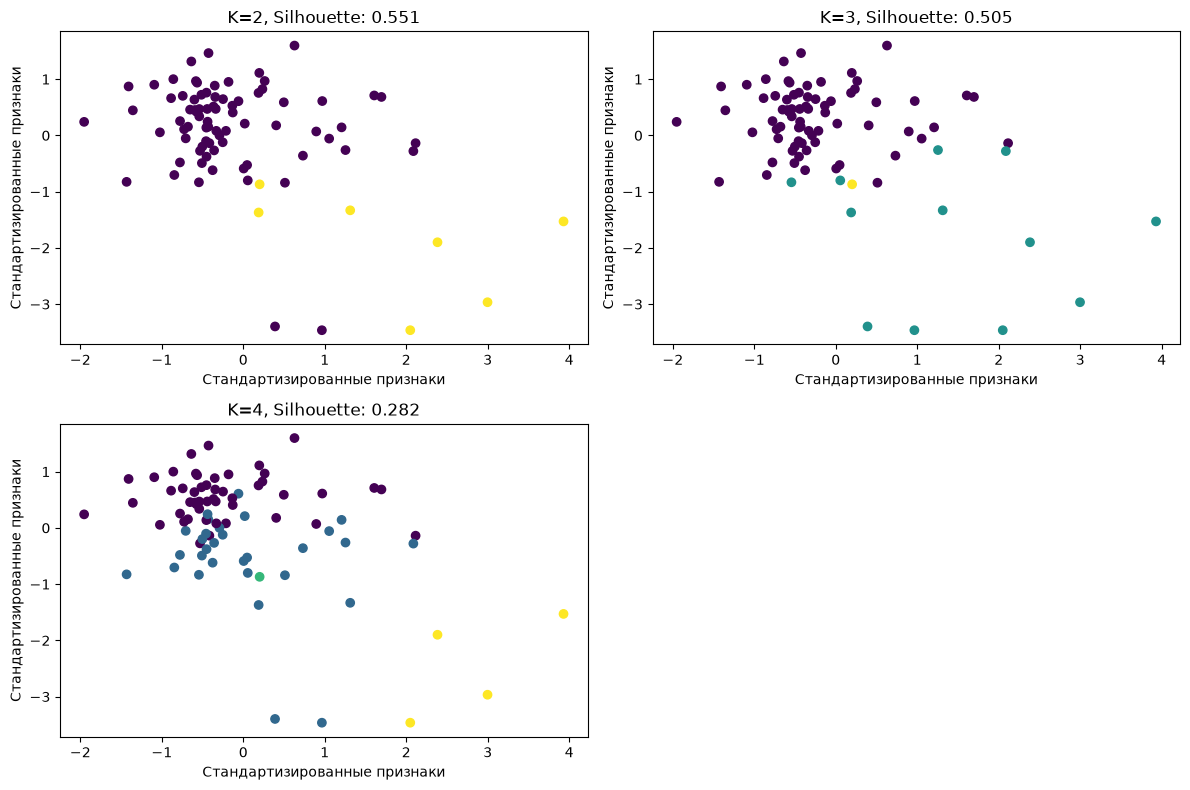


Анализ кластеров для k=2:

Кластер 0:
Регионы: Алтайский край, Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Вологодская область, Воронежская область, Еврейская автономная область, Забайкальский край, Ивановская область, Иркутская область, Кабардино-Балкарская Республика, Калужская область, Камчатский край, Карачаево-Черкесская Республика, Кемеровская область, Кировская область, Костромская область, Краснодарский край, Курганская область, Курская область, Ленинградская область, Липецкая область, Магаданская область, Московская область, Мурманская область, Нижегородская область, Новгородская область, Новосибирская область, Омская область, Оренбургская область, Орловская область, Пензенская область, Пермский край, Приморский край, Псковская область, Республика Адыгея, Республика Алтай, Республика Башкортостан, Республика Бурятия, Республика Дагестан, Республика Ингушетия, Республика Кал

In [75]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Стандартизация признаков
scaler = StandardScaler()
X = scaler.fit_transform(region_stats[['Среднее значение',
                                     'Коэфф. вариации',
                                     'Среднегодовой темп роста',
                                     'Относит. изменение',
                                     'Макс. падение',
                                     'Доля отрицат. динамики']])

# Результаты кластеризации для разных k
results = {}

for k in range(2, 5):
    kmeans = KMeans(n_clusters=k, random_state=42)
    region_stats[f'Кластер_{k}'] = kmeans.fit_predict(X)

    # Расчет silhouette score
    score = silhouette_score(X, region_stats[f'Кластер_{k}'])
    results[k] = {
        'score': score,
        'clusters': region_stats[f'Кластер_{k}'].unique()
    }

    print(f'Кластеров: {k}, Silhouette Score: {score:.3f}')

# Визуализация результатов
plt.figure(figsize=(12, 8))
for k in range(2, 5):
    plt.subplot(2, 2, k-1)
    plt.scatter(X[:, 0], X[:, 1], c=region_stats[f'Кластер_{k}'], cmap='viridis')
    plt.title(f'K={k}, Silhouette: {results[k]["score"]:.3f}')
    plt.xlabel('Стандартизированные признаки')
    plt.ylabel('Стандартизированные признаки')

plt.tight_layout()
plt.show()

# Анализ результатов кластеризации
for k in range(2, 5):
    print(f'\nАнализ кластеров для k={k}:')
    for cluster in region_stats[f'Кластер_{k}'].unique():
        cluster_data = region_stats[region_stats[f'Кластер_{k}'] == cluster]
        print(f'\nКластер {cluster}:')
        print(f'Регионы: {", ".join(cluster_data["region_name"])}')
        print(f'Среднее значение показателей:')
        print(cluster_data[['Среднее значение',
                          'Коэфф. вариации',
                          'Среднегодовой темп роста']].mean())


Кластеров: 2, Silhouette Score: 0.401
Кластеров: 3, Silhouette Score: 0.429
Кластеров: 4, Silhouette Score: 0.420


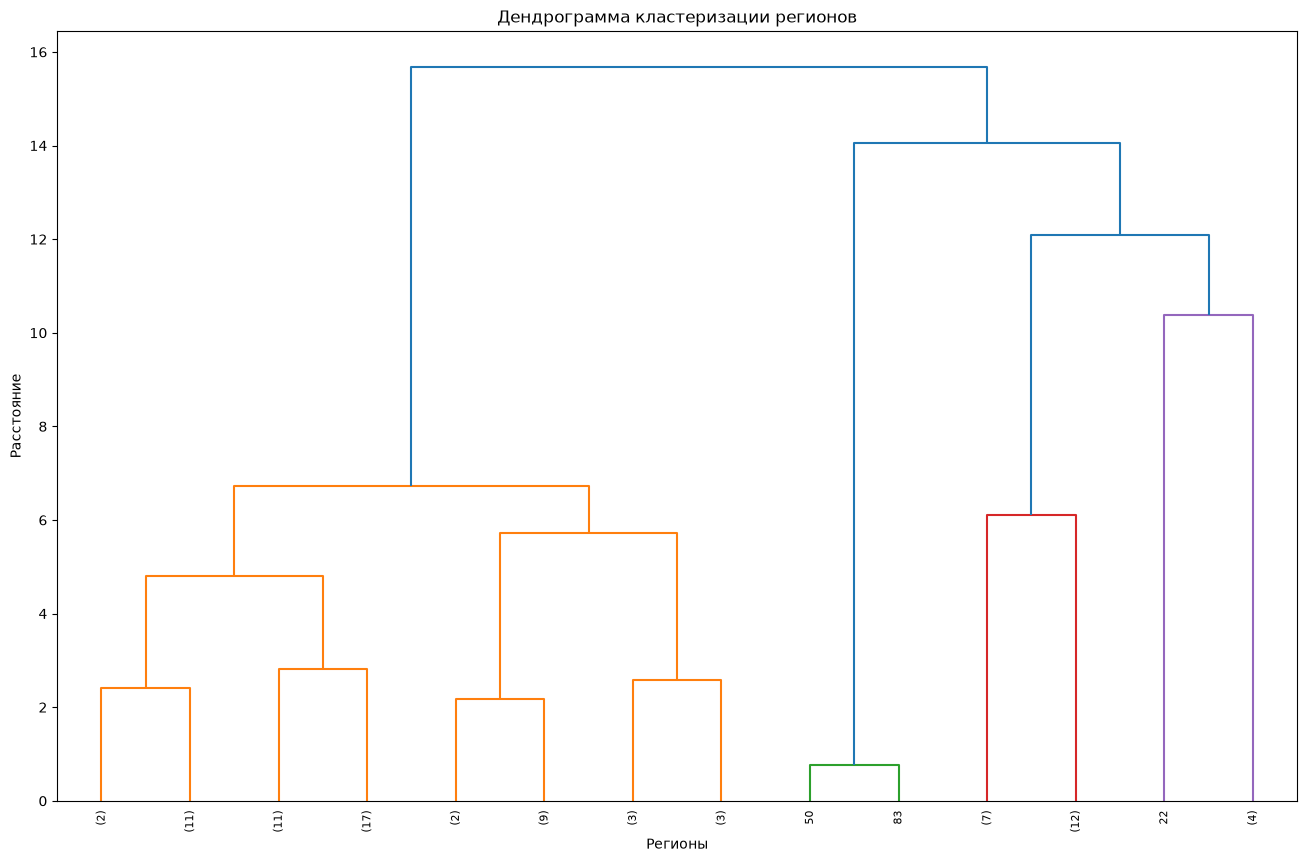


Анализ кластеров для k=2:

Кластер 0:
Регионы: Алтайский край, Воронежская область, Забайкальский край, Кемеровская область, Красноярский край, Курганская область, Ненецкий автономный округ, Омская область, Пермский край, Приморский край, Республика Дагестан, Республика Калмыкия, Республика Крым, Республика Саха (Якутия), Ростовская область, Самарская область, Свердловская область, Ставропольский край, Тамбовская область, Тюменская область, Ханты-Мансийский автономный округ – Югра, Челябинская область, Чукотский автономный округ, Ямало-Ненецкий автономный округ, г. Москва, г. Севастополь
Среднее значение показателей:
Среднее значение            253526.000417
Коэфф. вариации                 63.507359
Среднегодовой темп роста        16.715494
dtype: float64

Кластер 1:
Регионы: Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Вологодская область, Еврейская автономная область, Ивановская об

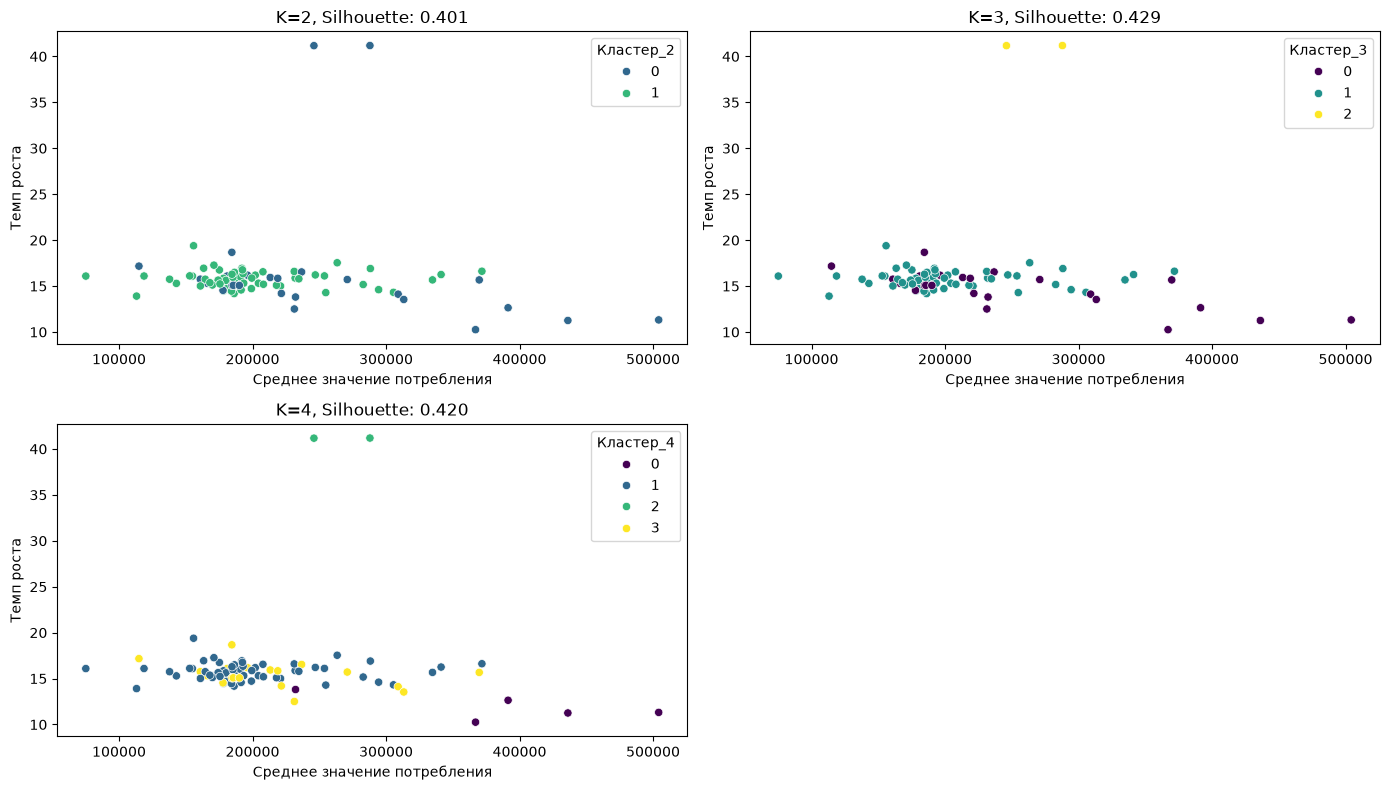

In [76]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Стандартизация признаков
scaler = StandardScaler()
X = scaler.fit_transform(region_stats[['Среднее значение',
                                     'Коэфф. вариации',
                                     'Среднегодовой темп роста',
                                     'Относит. изменение',
                                     'Макс. падение',
                                     'Доля отрицат. динамики']])

# Результаты кластеризации для разных k
results = {}

for k in range(2, 5):
    # Создаем модель агломеративной кластеризации
    agg_cluster = AgglomerativeClustering(n_clusters=k,  linkage='ward')
    region_stats[f'Кластер_{k}'] = agg_cluster.fit_predict(X)

    # Расчет silhouette score
    score = silhouette_score(X, region_stats[f'Кластер_{k}'])
    results[k] = {
        'score': score,
        'clusters': region_stats[f'Кластер_{k}'].unique()
    }

    print(f'Кластеров: {k}, Silhouette Score: {score:.3f}')

# Визуализация дендрограммы
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X, method='ward')
plt.figure(figsize=(16, 10))
dendrogram(Z,
           truncate_mode='level',
           p=3,
           leaf_rotation=90.,
           leaf_font_size=8.)
plt.title('Дендрограмма кластеризации регионов')
plt.xlabel('Регионы')
plt.ylabel('Расстояние')
plt.show()

# Анализ результатов кластеризации
for k in range(2, 5):
    print(f'\nАнализ кластеров для k={k}:')
    for cluster in region_stats[f'Кластер_{k}'].unique():
        cluster_data = region_stats[region_stats[f'Кластер_{k}'] == cluster]
        print(f'\nКластер {cluster}:')
        print(f'Регионы: {", ".join(cluster_data["region_name"])}')
        print(f'Среднее значение показателей:')
        print(cluster_data[['Среднее значение',
                          'Коэфф. вариации',
                          'Среднегодовой темп роста']].mean())

# Визуализация кластеров
plt.figure(figsize=(14, 8))
for k in range(2, 5):
    plt.subplot(2, 2, k-1)
    sns.scatterplot(x='Среднее значение',
                   y='Среднегодовой темп роста',
                   hue=f'Кластер_{k}',
                   data=region_stats,
                   palette='viridis')
    plt.title(f'K={k}, Silhouette: {results[k]["score"]:.3f}')
    plt.xlabel('Среднее значение потребления')
    plt.ylabel('Темп роста')

plt.tight_layout()
plt.show()



Анализ региона: г. Москва


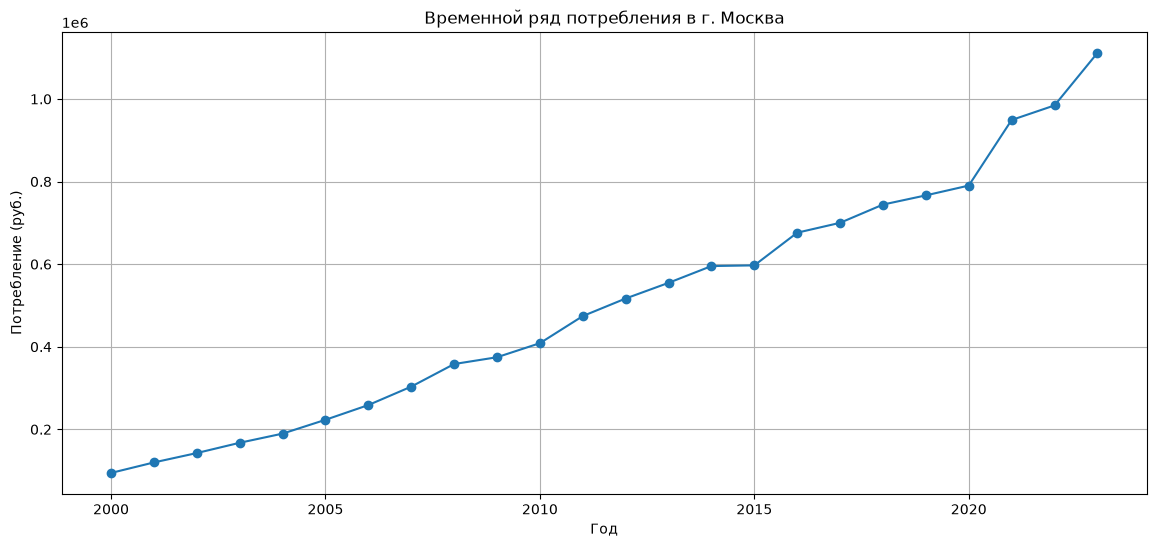

Статистика теста Дики-Фуллера: 2.7387840801779273
p-значение: 0.9990880788395473


/tmp/ipykernel_54785/1990415788.py:55: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(time_series[region].dropna())


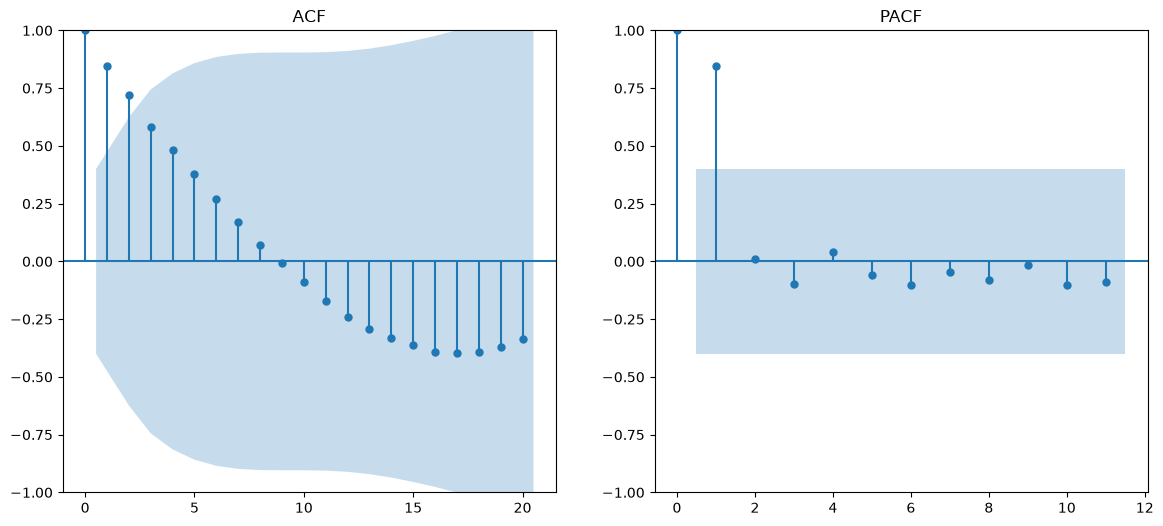

Среднее значение: 504,230.94
Стандартное отклонение: 293,379.24
Прирост за 2000–2023 гг.: 1077.24%
Среднегодовой прирост (CAGR): 11.32%



Анализ региона: Московская область


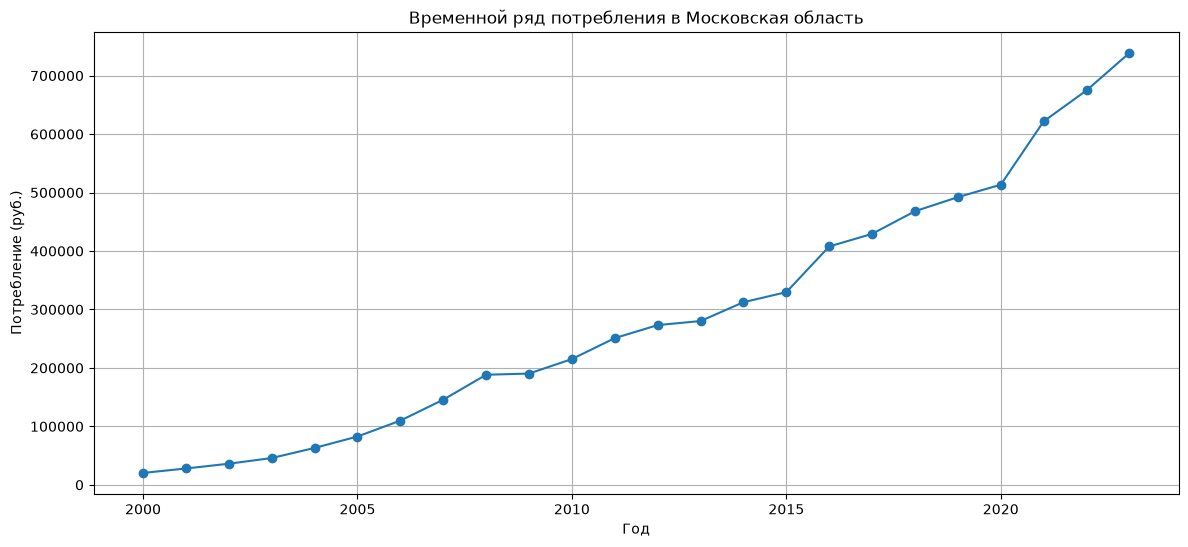

Статистика теста Дики-Фуллера: 3.2340588576059965
p-значение: 1.0


/tmp/ipykernel_54785/1990415788.py:55: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(time_series[region].dropna())


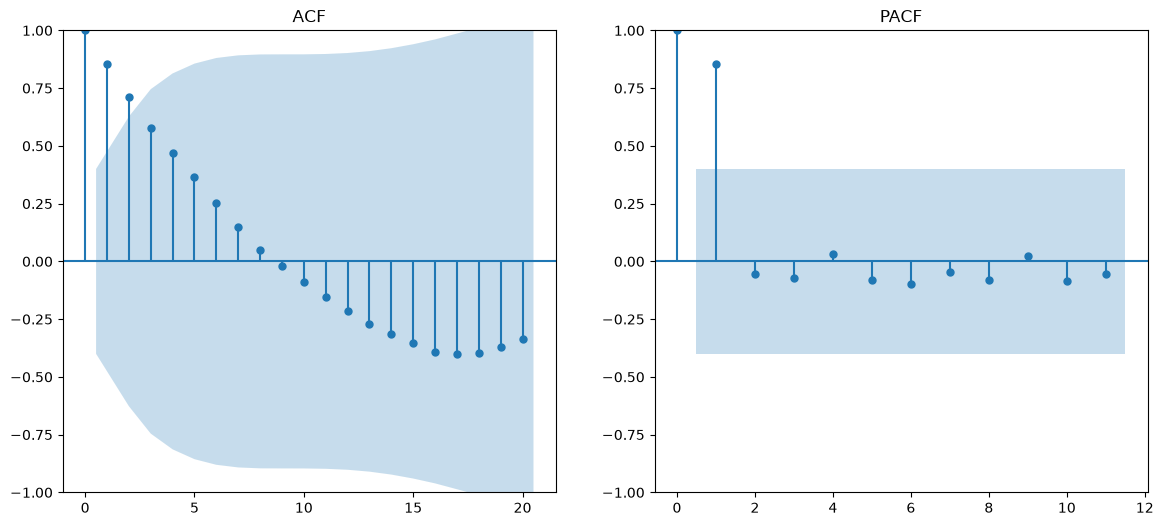

Среднее значение: 288,251.08
Стандартное отклонение: 214,508.50
Прирост за 2000–2023 гг.: 3533.04%
Среднегодовой прирост (CAGR): 16.91%



Анализ региона: Белгородская область


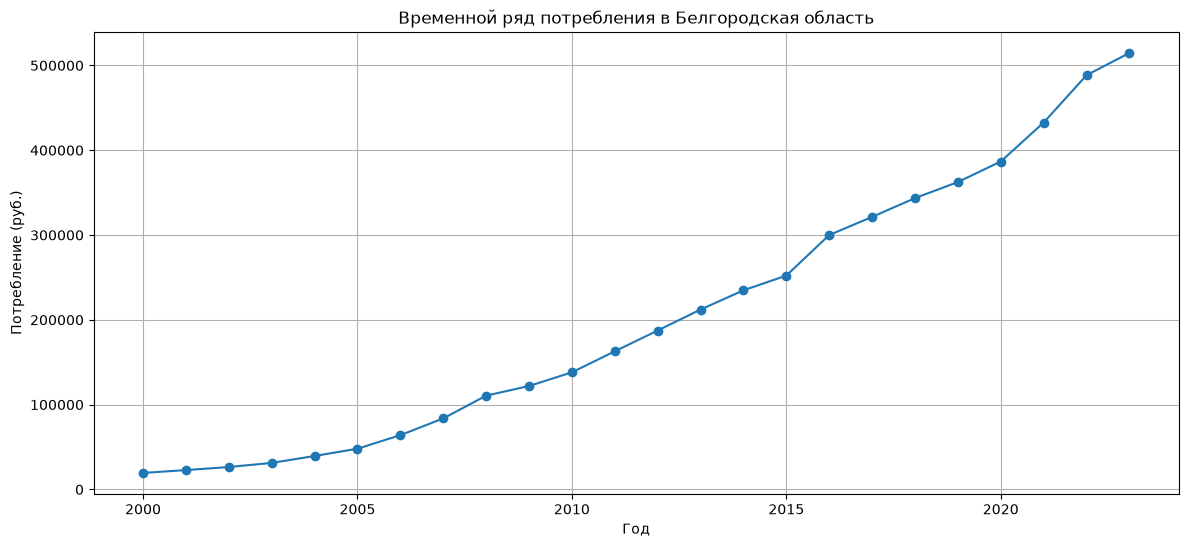

Статистика теста Дики-Фуллера: 2.2382174032048865
p-значение: 0.9989125060131252


/tmp/ipykernel_54785/1990415788.py:55: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(time_series[region].dropna())


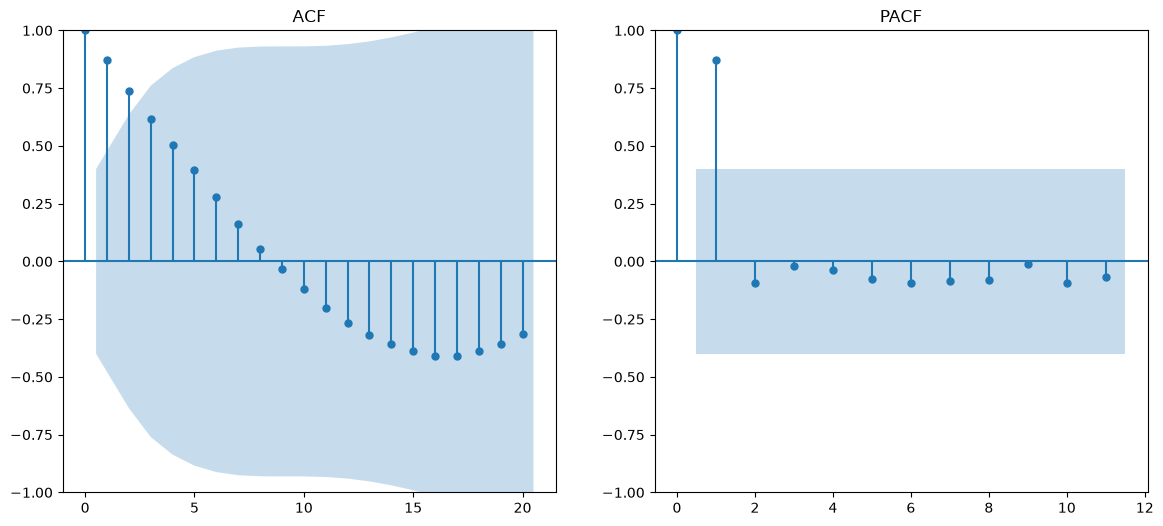

Среднее значение: 204,367.34
Стандартное отклонение: 157,363.94
Прирост за 2000–2023 гг.: 2550.33%
Среднегодовой прирост (CAGR): 15.31%




In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Читаем данные
df = pd.read_csv('data/rsdocs_1491005410458_wide_appendix_2025.csv',
                encoding='utf-8',
                dtype=str,
                na_values=['…', ''])

# Выбираем три региона
regions = ['г. Москва', 'Московская область', 'Белгородская область']
data = df[df['region_name'].isin(regions)]

# Преобразуем в длинный формат
df_long = data.melt(
    id_vars=['region_name', 'region_code', 'indicator_name', 'measure_unit'],
    value_vars=[col for col in data.columns if col.isdigit()],
    var_name='year',
    value_name='value'
)
df_long = df_long.dropna()
# Преобразуем типы данных
df_long['year'] = df_long['year'].astype(int)

df_long['value'] = pd.to_numeric(
    df_long['value'].str.replace(',', '.', regex=False)
)


# Создаем отдельные временные ряды
time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()

# Анализ каждого региона
for region in regions:
    print(f"\nАнализ региона: {region}")

    # Исходный ряд
    plt.figure(figsize=(14, 6))
    plt.plot(time_series[region], marker='o')
    plt.title(f'Временной ряд потребления в {region}')
    plt.xlabel('Год')
    plt.ylabel('Потребление (руб.)')
    plt.grid(True)
    plt.show()

    # Скользящее среднее для выявления тренда
    time_series[region + '_ma'] = time_series[region].rolling(window=3).mean()

    # Тест Дики-Фуллера на стационарность
    result = adfuller(time_series[region].dropna())
    print(f"Статистика теста Дики-Фуллера: {result[0]}")
    print(f"p-значение: {result[1]}")

    # ACF требует лаг < n; для PACF используем лаг < n // 2.
    series = time_series[region].dropna()
    acf_lags = min(20, len(series) - 1)
    pacf_lags = min(20, len(series) // 2 - 1)

    plt.figure(figsize=(14, 6))
    plt.subplot(121)
    plot_acf(series, ax=plt.gca(), lags=acf_lags)
    plt.title('ACF')

    plt.subplot(122)
    plot_pacf(series, ax=plt.gca(), lags=pacf_lags)
    plt.title('PACF')
    plt.show()

    # Выводы
    print(f"Среднее значение: {time_series[region].mean():,.2f}")
    print(f"Стандартное отклонение: {time_series[region].std():,.2f}")
    total_growth = (series.iloc[-1] / series.iloc[0] - 1) * 100
    years = series.index[-1] - series.index[0]
    annual_growth = ((series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1) * 100
    print(f"Прирост за {series.index[0]}–{series.index[-1]} гг.: {total_growth:.2f}%")
    print(f"Среднегодовой прирост (CAGR): {annual_growth:.2f}%")
    print("\n")


In [ ]:

import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.base import ForecastingHorizon
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


forecast_results = {}

for colunn in regions:
    data = time_series[colunn].sort_index().copy()
    data.index = pd.PeriodIndex(data.index.astype(str), freq='Y')
    train_size = int(len(data) * 0.8)
    train = data.iloc[:train_size]
    test = data.iloc[train_size:]
    print(f'{colunn}: train={len(train)}, test={len(test)}')
        # ---------------------------------------------------------
    # 2. NaiveForecaster (last observation) — sktime
    # ---------------------------------------------------------
    fh = ForecastingHorizon(test.index, is_relative=False)
    naive_model = NaiveForecaster(strategy="last")
    naive_model.fit(train)
    naive_pred = naive_model.predict(fh)

    # ---------------------------------------------------------
    # 3. Holt (экспоненциальное сглаживание с трендом)
    #    без сезонности, т.к. данные годовые
    # ---------------------------------------------------------
    holt_model = ExponentialSmoothing(
        train,
        trend='add',          # аддитивный тренд
        seasonal=None,        # нет сезонности
        initialization_method='estimated'
    )
    holt_fit = holt_model.fit()
    holt_pred = holt_fit.forecast(steps=len(test),)

    # ---------------------------------------------------------
    # 4. ARIMA: ручной подбор vs auto_arima (pmdarima)
    # ---------------------------------------------------------
    # Вариант A: автоподбор порядка (p,d,q)
    arima_auto = auto_arima(
        train,
        start_p=0, max_p=5,
        d=None, max_d=2,          # d подберётся автоматически
        start_q=0, max_q=5,
        seasonal=False,           # годовые данные, сезонности нет
        trace=False,
        suppress_warnings=True,
        stepwise=True
    )
    arima_pred_auto = arima_auto.predict(n_periods=len(test))

    # Вариант B: ручная спецификация (пример ARIMA(1,1,1))
    arima_manual = ARIMA(train, order=(1, 1, 1))
    arima_fit_manual = arima_manual.fit()
    arima_pred_manual = arima_fit_manual.forecast(steps=len(test))

    # ---------------------------------------------------------
    # 5. Оценка качества (MAE, RMSE, MAPE)
    # ---------------------------------------------------------
    def mape(y_true, y_pred):
        return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    metrics = {}
    for name, pred in [
        ("Naive", naive_pred),
        ("Holt", holt_pred),
        ("ARIMA_auto", arima_pred_auto),
        ("ARIMA_manual", arima_pred_manual)
    ]:
        mae = mean_absolute_error(test, pred)
        rmse = np.sqrt(mean_squared_error(test, pred))
        mape_val = mape(test, pred)
        metrics[name] = {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape_val}

    # Сохраняем результаты всех регионов для оценки устойчивости.
    forecast_results[colunn] = {
        'data': data.copy(),
        'train_size': train_size,
        'metrics': metrics,
        'predictions': {
            'Naive': naive_pred.copy(),
            'Holt': holt_pred.copy(),
            'ARIMA_auto': arima_pred_auto.copy(),
            'ARIMA_manual': arima_pred_manual.copy(),
        },
    }

    print("Метрики качества:")
    for k, v in metrics.items():
        print(f"{k}: MAE={v['MAE']:.2f}, RMSE={v['RMSE']:.2f}, MAPE={v['MAPE (%)']:.2f}%")

    # ---------------------------------------------------------
    # 6. Визуализация
    # ---------------------------------------------------------
    plt.figure(figsize=(10, 6))
    plt.plot(train.index.year, train, label='Train', marker='o')
    plt.plot(test.index.year, test, label='Test', marker='s', color='black')
    plt.plot(naive_pred.index.year, naive_pred, label='Naive (last)', linestyle='--')
    plt.plot(holt_pred.index.year, holt_pred, label='Holt', linestyle='-.')
    plt.plot(arima_pred_auto.index.year, arima_pred_auto, label='ARIMA (auto)', linestyle=':')
    plt.title('Сравнение моделей прогнозирования')
    plt.xlabel('Год')
    plt.ylabel('Значение показателя')
    plt.legend()
    plt.grid(True)
    plt.show()

### Оценка устойчивости: rolling forecast

Для каждого региона выбираем модель с минимальным RMSE на исходной тестовой
выборке. Размер обучающего окна фиксирован и равен исходному размеру train.
На каждом шаге модель заново обучается, прогнозирует следующий год, после чего
окно сдвигается на один год: самое старое наблюдение исключается, а фактическое
значение уже прошедшего года добавляется. Будущие значения при обучении недоступны.
Для ARIMA_auto порядок заново подбирается только на текущем окне.

Сравниваем RMSE и MAPE на тех же тестовых годах, а также ошибки по годам.
Исходный прогноз сделан сразу на весь тест, rolling — на один шаг с ежегодным
обновлением данных. Поэтому различие ошибок отражает и различие горизонтов.
Выбор лучшей модели по этому же тесту делает сравнение исследовательским;
для независимой итоговой оценки нужен отдельный контрольный период.


In [ ]:
from IPython.display import display


def rolling_predict_one_step(model_name, window):
    """Переобучить выбранную модель на текущем окне и предсказать один год."""
    if model_name == 'Naive':
        model = NaiveForecaster(strategy='last')
        model.fit(window)
        prediction = model.predict(fh=[1])
    elif model_name == 'Holt':
        model = ExponentialSmoothing(
            window, trend='add', seasonal=None,
            initialization_method='estimated',
        ).fit()
        prediction = model.forecast(steps=1)
    elif model_name == 'ARIMA_manual':
        model = ARIMA(window, order=(1, 1, 1)).fit()
        prediction = model.forecast(steps=1)
    elif model_name == 'ARIMA_auto':
        model = auto_arima(
            window, start_p=0, max_p=5, d=None, max_d=2,
            start_q=0, max_q=5, seasonal=False, trace=False,
            suppress_warnings=True, stepwise=True,
        )
        prediction = model.predict(n_periods=1)
    else:
        raise ValueError(f'Неизвестная модель: {model_name}')
    return float(np.asarray(prediction).reshape(-1)[0])


rolling_results = {}
comparison_rows = []

for region, saved in forecast_results.items():
    data = saved['data']
    window_size = saved['train_size']
    test = data.iloc[window_size:]
    best_model = min(saved['metrics'], key=lambda name: saved['metrics'][name]['RMSE'])
    fixed_prediction = saved['predictions'][best_model]

    predictions = []
    window_records = []
    for position in range(window_size, len(data)):
        # position — год прогноза; правая граница iloc исключена.
        window = data.iloc[position - window_size:position]
        predictions.append(rolling_predict_one_step(best_model, window))
        window_records.append({
            'Начало окна': window.index[0].year,
            'Конец окна': window.index[-1].year,
            'Размер окна': len(window),
        })

    rolling_prediction = pd.Series(predictions, index=test.index, name='Rolling')
    actual = test.to_numpy(dtype=float)
    predicted = rolling_prediction.to_numpy(dtype=float)
    rolling_rmse = np.sqrt(mean_squared_error(actual, predicted))
    rolling_mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    fixed_metrics = saved['metrics'][best_model]
    rmse_change = (rolling_rmse / fixed_metrics['RMSE'] - 1) * 100

    details = pd.DataFrame(window_records, index=test.index)
    details['Факт'] = test
    details['Исходный прогноз'] = fixed_prediction
    details['Rolling прогноз'] = rolling_prediction
    details['Ошибка rolling (прогноз − факт)'] = predicted - actual
    details['Абсолютная ошибка rolling'] = np.abs(predicted - actual)
    details['APE rolling (%)'] = np.abs((actual - predicted) / actual) * 100
    rolling_results[region] = {'model': best_model, 'details': details}
    comparison_rows.append({
        'Регион': region,
        'Модель': best_model,
        'RMSE исходный': fixed_metrics['RMSE'],
        'RMSE rolling': rolling_rmse,
        'Изменение RMSE (%)': rmse_change,
        'MAPE исходный (%)': fixed_metrics['MAPE (%)'],
        'MAPE rolling (%)': rolling_mape,
    })

    print(f'\n{region}: {best_model}, окно {window_size} лет')
    display(details.round(2))
    if rmse_change < 0:
        print(f'При ежегодном обновлении RMSE ниже на {abs(rmse_change):.2f}%.')
    else:
        print(f'При ежегодном обновлении RMSE выше на {rmse_change:.2f}%.')
    worst_year = details['Абсолютная ошибка rolling'].idxmax()
    print(f'Максимальная абсолютная ошибка rolling: {worst_year.year} год, '
          f"{details.loc[worst_year, 'Абсолютная ошибка rolling']:,.2f} руб.")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    years = test.index.year
    axes[0].plot(years, test, marker='o', color='black', label='Факт')
    axes[0].plot(years, fixed_prediction, marker='s', linestyle='--',
                 label='Исходный прогноз на весь тест')
    axes[0].plot(years, rolling_prediction, marker='o', label='Rolling: один шаг')
    axes[0].set(title=f'{region}: {best_model}', xlabel='Год', ylabel='Потребление, руб.')
    axes[0].legend()
    axes[1].plot(years, details['APE rolling (%)'], marker='o', label='Rolling')
    fixed_ape = np.abs((actual - fixed_prediction.to_numpy()) / actual) * 100
    axes[1].plot(years, fixed_ape, marker='s', linestyle='--', label='Исходный прогноз')
    axes[1].set(title='Ошибка по годам', xlabel='Год', ylabel='Абсолютная ошибка, %')
    axes[1].legend()
    for ax in axes:
        ax.set_xticks(years)
        ax.grid(True)
    plt.tight_layout()
    plt.show()

rolling_comparison = pd.DataFrame(comparison_rows).set_index('Регион')
print('Сравнение на одинаковых тестовых годах (меньше RMSE и MAPE — лучше):')
display(rolling_comparison.round(2))


### Вывод об устойчивости прогнозов

На тестовых годах 2019–2023 ежегодное переобучение со скользящим окном из
19 наблюдений снизило ошибки выбранных моделей:

| Регион | Модель по исходному RMSE | RMSE исходный → rolling, руб. | MAPE исходный → rolling | Снижение RMSE |
|---|---|---|---|---|
| г. Москва | ARIMA_auto | 103 102,74 → 69 556,20 | 8,23% → 5,72% | 32,54% |
| Московская область | ARIMA_manual | 66 389,73 → 39 464,69 | 8,22% → 4,42% | 40,56% |
| Белгородская область | ARIMA_auto | 20 869,31 → 17 248,86 | 4,45% → 3,12% | 17,35% |

На этом периоде обновление моделей улучшило точность для всех трёх регионов.
Наибольшее относительное снижение RMSE наблюдается у Московской области.
MAPE rolling минимален у Белгородской области, что указывает на меньшую
относительную ошибку её прогноза на рассмотренных годах.
Однако пять тестовых наблюдений недостаточны для вывода о стабильности на
других периодах; улучшение также связано с переходом от прогноза сразу на пять
лет к прогнозам на один год с обновлением фактических данных.
